In [1]:
import xarray as xr
import os
import glob
import numpy as np
import warnings
import matplotlib.pyplot as plt
import sys
import cmocean


In [6]:
surf = xr.open_mfdataset('/scratch/pp2681/mom6/CORE-AIF-runs/unparameterized/*ocean_daily_*', parallel=True, combine='nested', compat='no_conflicts', concat_dim='time').sortby('time')

In [11]:
zos = surf.zos.sel(xh=slice(-60,-40), yh=slice(25,45)).compute()

In [14]:
zos.to_dataset().to_netcdf('zos_Gulf.nc')

In [2]:
zos = xr.open_dataset('zos_Gulf.nc').zos

In [3]:
zos_5d = zos.coarsen({'time':5}).mean().compute()

In [4]:
zos_climatology = zos_5d.groupby('time.dayofyear').mean('time')

In [5]:
zos_anom = zos_5d.groupby('time.dayofyear') - zos_climatology

In [7]:
zos_anom.to_dataset().to_netcdf('zos_Gulf_anomaly.nc')

In [2]:
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.correlate.html#scipy.signal.correlate
import scipy
def correlate(_x, time_increment=1, demean=False, normalize=True):
    if demean:
        x = _x.copy()
        x = x - np.mean(x)
    else:
        x = _x.copy()
    corr = scipy.signal.correlate(x, x, mode='full')
    if normalize:
        corr = corr / corr[len(corr) // 2]  # Normalize by the zero-lag value
    lags = scipy.signal.correlation_lags(len(x), len(x))
    return lags * time_increment, corr

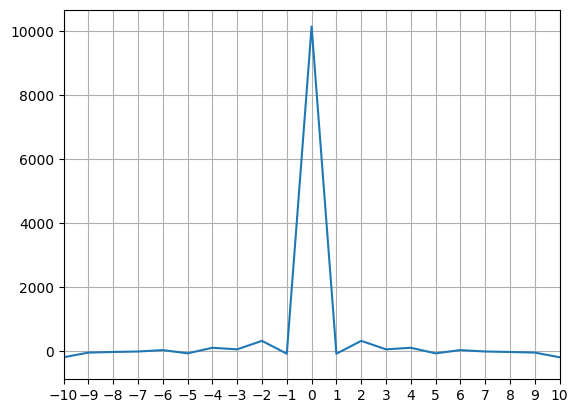

In [66]:
x = np.random.randn(10000)
plt.plot(*correlate(x, demean=True, normalize=False))
plt.xlim([-10,10])
plt.xticks(np.arange(-10,11,1))
plt.grid()

In [4]:
zos_anom = xr.open_dataset('zos_Gulf_anomaly.nc').transpose('yh', 'xh', 'time').zos.compute()

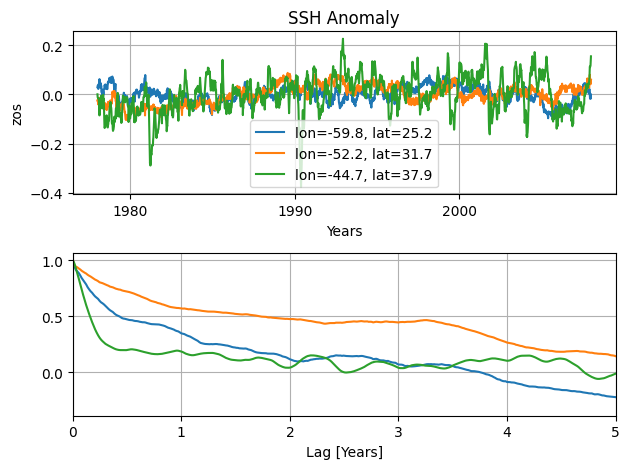

In [63]:
for (i,j) in [(0,0), (30,30), (60,60)]:
    x = zos_anom[i,j]
    plt.subplot(2,1,1)
    x.plot(label='lon={}, lat={}'.format(round(zos_anom.xh[i].item(),1), round(zos_anom.yh[j].item(),1)))
    plt.title('SSH Anomaly')
    plt.xlabel('Years')
    plt.subplot(2,1,2)
    plt.plot(*correlate(x, time_increment=5/365, demean=True))
    plt.xlim([0, 5])
    plt.xlabel('Lag [Years]')
    plt.xticks(np.arange(0,6,1))

plt.subplot(2,1,1)
plt.grid()
plt.legend()
plt.subplot(2,1,2)
plt.grid()

plt.tight_layout()

# Variance-weighted averaging of autocorrelation

In [5]:
lags, corr = correlate(zos_anom[0,0], time_increment=5/365, demean=True)
corr = corr * 0
for i in range(zos_anom.shape[0]):
    for j in range(zos_anom.shape[1]):
        corr += correlate(zos_anom[i,j], time_increment=5/365, demean=True, normalize=False)[1]
corr = corr / corr[len(corr) // 2]  # Normalize by the zero-lag value

In [75]:
corr

array([-7.9726589e-05, -1.6877969e-04, -2.3333196e-04, ...,
       -2.3333196e-04, -1.6877969e-04, -7.9726589e-05], dtype=float32)

Text(0, 0.5, 'SSH anomaly autocorrelation')

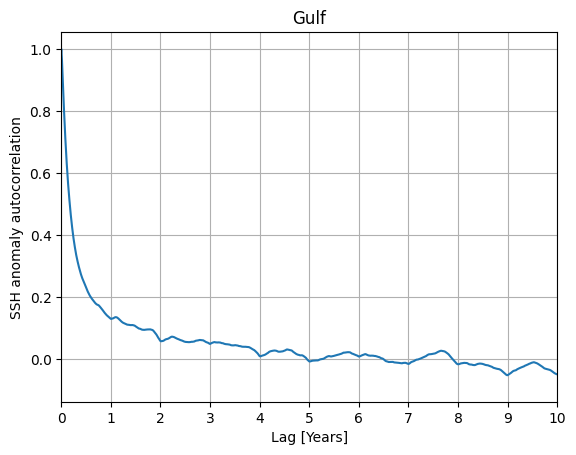

In [10]:
plt.plot(lags, corr)
plt.xlim([0, 10])
plt.xlabel('Lag [Years]')
plt.xticks(np.arange(0,11,1));
plt.grid()
plt.title('Gulf')
plt.ylabel('SSH anomaly autocorrelation')

# Power spectrum

In [24]:
import xrft
x = zos_anom.drop_vars('dayofyear').copy()
x['time'] = np.arange(len(x.time)) * 5/365 # Years
power = xrft.power_spectrum(x, dim='time', detrend='linear', window='hann').mean('xh').mean('yh')

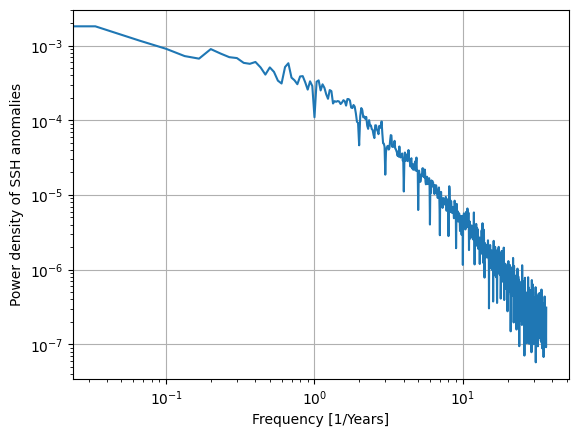

In [30]:
power.plot(xscale='log', yscale='log')
plt.xticks([0.1, 1, 10])
plt.xlabel('Frequency [1/Years]')
plt.ylabel('Power density of SSH anomalies')
plt.grid();